# Multi frame prediction and saving new annotations in COCO format

''''

| ファイル名                             | 内容                                   | 加工の流れ                                                                       |
| --------------------------------- | ------------------------------------ | --------------------------------------------------------------------------- |
| `〇〇_prediction.png`               | モデルの**パッチ推論結果マスク（グレースケール）**          | 各パッチに `predict_multi_frame()` を適用し、全体に統合                                    |
| `〇〇_prediction.npy`               | 6チャンネル統合データ<br>（マスク・ラベル・元画像など）       | `img_pred`, `new_labels`, `expanded_labels`, `cleared_labels`, `img_in` を結合 |
| `〇〇_new_label.png`                | `img_pred > 0` を2値化→`label()`で連番ラベル化 | 細胞ごとの領域IDを付与                                                                |
| `〇〇_expanded_labels.png` / `.npy` | `new_labels` を `expand_labels()` で拡張 | 細胞領域を25ピクセル膨張                                                               |
| `〇〇_new_annot.png`                | ラベルごとに推論クラス（グレイ値）を再割当てした最終マスク        | 属性テーブルの分類結果を `new_labels` に再投影                                              |
| `〇〇_annot_coco.json`              | 上記マスクをもとに作成された COCO形式アノテーションファイル     | `create_category_annotation` などを用いて構築                                       |
| `evaluation_metrics.csv`          | 推論結果の精度（IoU/Dice/Accuracy）を1行で記録     | GTマスクとの比較から算出、毎回追記                                                          |

''''

''''

img_pred
   ↓
label(img_pred > 0) → new_labels
   ↓ expand_labels → expanded_labels
   ↓ clear_border → cleared_labels
   ↓ regionprops → df (gray, anatomy)
   ↓ map label → gray → new_annot.png
                     ↓
                  → coco.json
                     ↓
         compare with GT → evaluation_metrics.csv
         
''''

In [1]:
import torch
import cv2
import os
import numpy as np
from tqdm import tqdm
from PIL import Image
import matplotlib.pyplot as plt
import time
import itertools
import pandas as pd

from skimage import data, graph
from skimage.filters import threshold_otsu
from skimage.measure import label, regionprops, regionprops_table
from skimage.morphology import closing, square
from skimage.color import label2rgb
from skimage.segmentation import expand_labels, clear_border

import torch.nn as nn
import torch.nn.functional as F
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

###### Semantic and mask segmentation Model : Mask-RCNN-FPN.v2
#### Model used is 256_Sapindaceae_222_epoch.tar : based on 256x256 data after 222 epoch

The large image is divided into patches, and instance cell segmentation was preformed from each patches. Next, results are unpatched and pasted together so that the boundary parts are not noticeable.
From the image obtained, (A) the predicted regional information is saved in coco-format, and (B) the region adjacency graph after region expansion is created and saved. (A) is used for modification or collection of predicted annotation with coco_anotator software (MIT), and (B) is used for preliminary analysis of the cell-cell network.

### Read prediction model

In [2]:

class GradientReversalLayer(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -grad_output.clone(),

class DomainClassifier(nn.Module):
    def __init__(self, in_features=256, hidden_size=128, num_domains=6):
        super(DomainClassifier, self).__init__()
        self.classifier = nn.Sequential(
            nn.Linear(in_features, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_domains)
        )

    def forward(self, x):
        return self.classifier(x)

class CustomMaskRCNN(nn.Module):
    def __init__(self, num_classes=5, num_domains=6):
        super(CustomMaskRCNN, self).__init__()
        self.model = maskrcnn_resnet50_fpn_v2(weights="DEFAULT")
        in_features = self.model.roi_heads.box_predictor.cls_score.in_features
        self.model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

        self.domain_classifier = DomainClassifier(in_features=256, num_domains=num_domains)
        self.grl = GradientReversalLayer.apply

    def forward(self, images, targets=None):
        # 推論時は Mask R-CNN に直接渡すだけ
        if not self.training:
            return self.model(images)
    
        # ↓↓↓ 学習時のみ特徴マップ抽出とドメイン分類を行う
        features = self.model.backbone(images.tensors if hasattr(images, "tensors") else images)
        feat_map = features["0"]
        pooled_feat = F.adaptive_avg_pool2d(feat_map, (1, 1)).view(feat_map.size(0), -1)
        reversed_feat = self.grl(pooled_feat)
        domain_pred = self.domain_classifier(reversed_feat)
    
        if isinstance(targets, list) and "domain_id" in targets[0]:
            domain_labels = torch.stack([t["domain_id"] for t in targets]).to(domain_pred.device)
            domain_loss = F.cross_entropy(domain_pred, domain_labels)
        else:
            domain_loss = torch.tensor(0.0, device=domain_pred.device)
    
        loss_dict = self.model(images, targets)
        if isinstance(loss_dict, dict):
            loss_dict["domain_loss"] = domain_loss
    
        return loss_dict



def get_model(num_classes=5, num_domains=6):
    model = CustomMaskRCNN(num_classes=num_classes, num_domains=num_domains)
    return model

In [3]:
import os
import torch
#from src.load_mrcnn import get_model, load_checkpoint, predict_multi_frame
from src.load_mrcnn import predict_multi_frame

''' set gpu to be used '''
GPU_ID = 0
DEVICE = torch.device(f'cuda:{GPU_ID}' if torch.cuda.is_available() else 'cpu')
''' set image size to be used '''
image_size = 256  # choice is 256 or 512
IMAGE_SIZE = [image_size, image_size] 
''' set test image to read '''
TEST_DIR = 'dataset/png_'+str(image_size)+'/image/test'

''' load mrcnn model 
    models are stored in the directory ./model
'''
MODEL_FILE = "512_thin_multidomain_700_epoch.tar"


LEARNING_RATE = 1e-5
WEIGHT_DECAY = 5e-4

model = get_model(num_classes=5, num_domains=6)
model.to(DEVICE)

checkpoint = torch.load(os.path.join('./model', MODEL_FILE), map_location=DEVICE)
model.load_state_dict(checkpoint['state_dict'])  # ← ← ← ココが重要


model.eval()

print(f"GPU:{torch.cuda.current_device()} will be used for calculation!")


/tmp/ipykernel_3358408/766768970.py:26: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(os.path.join('./model', MODEL_FILE), map_location=DEVICE)


GPU:0 will be used for calculation!


## Prediction

In [4]:
model.train(False)

img_num = 1

testfilename = [fl for fl in os.listdir(TEST_DIR) if fl.endswith('.png')]
print('You have ', str(len(testfilename)-1), \
      ' test images, and you selected image No. ', str(img_num))
img0 = Image.open(os.path.join(TEST_DIR,testfilename[img_num])).convert('RGB')


You have  47  test images, and you selected image No.  1


Check model using test image !

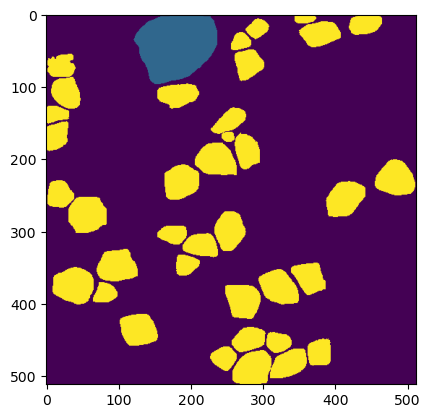

In [5]:
img = cv2.imread(os.path.join(TEST_DIR,testfilename[img_num]))
res2 = predict_multi_frame(model, img, IMAGE_SIZE, 0.7, 0.7, DEVICE)
plt.imshow(res2)
plt.show()

I decided to cut out a 320x320 central part of a 512x512 image and paste it together to recover original size.

First, an image with 96 pixels of padding in four directions was created, and for every 512x512 image cut out with a shift of 320 pixels, a label was predicted, and the central 320x320 of the predicted image was cut out and stored in an array of the same size as the empty original image.

sz: スライディングウィンドウの移動ステップ
pad: モデル入力に必要な余白サイズ（パッチサイズは sz + 2*pad）
l: range(N)：画像を sz ピクセルごとに N 回スライドさせるためのインデックスリスト

Processing dataset/performance_check/image/acapod2_01_img.png ...


Inference on acapod2_01_img.png: 16it [00:01,  9.13it/s]


acapod2_01_img: 推論完了 (GPU time = 1.76 sec)
Processing dataset/performance_check/image/alllit2_01_img.png ...


Inference on alllit2_01_img.png: 16it [00:01,  9.37it/s]


alllit2_01_img: 推論完了 (GPU time = 1.71 sec)
Processing dataset/performance_check/image/burspi1_01_img.png ...


Inference on burspi1_01_img.png: 16it [00:01,  8.98it/s]


... (3 outputs left out)

Inference on exostr8_01_img.png: 16it [00:01,  9.56it/s]


exostr8_01_img: 推論完了 (GPU time = 1.68 sec)
Processing dataset/performance_check/image/hakdac2_01_img.png ...


Inference on hakdac2_01_img.png: 16it [00:01,  9.69it/s]


hakdac2_01_img: 推論完了 (GPU time = 1.65 sec)


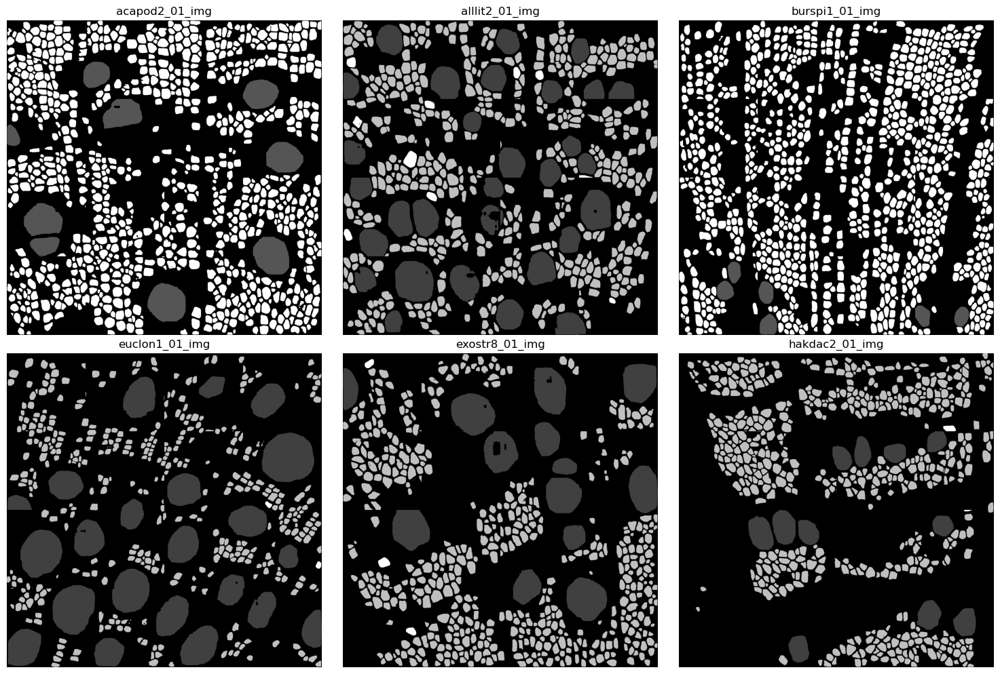

In [6]:

# 推論対象の画像一覧
sp_to_filename = {
    "acapod": "acapod2_01_img.png",
    "alllit": "alllit2_01_img.png",
    "burspi": "burspi1_01_img.png",
    "euclon": "euclon1_01_img.png",
    "exostr": "exostr8_01_img.png",
    "hakdac": "hakdac2_01_img.png"
}

input_dir = 'dataset/performance_check/image'
gt_dir = 'dataset/performance_check/mask'
base_dir = './inference_results_without_clearborder'



# 画像サイズに応じたパラメータ設定
if image_size == 512:
    pad = 64
    sz = 384
    l = list(range(4))
elif image_size == 256:
    pad = 32
    sz = 192
    l = list(range(8))
else:
    raise ValueError(f"Unsupported image_size: {image_size}")



# 推論結果を保存しておくリスト（表示用）
predictions = []
label_results = []


# 推論ループ
for sp, filename in sp_to_filename.items():
    data_img = os.path.join(input_dir, filename)
    print(f"Processing {data_img} ...")

    img_in = cv2.imread(data_img)
    if img_in is None:
        print(f"読み込みエラー: {data_img}")
        continue

    img_padded = cv2.copyMakeBorder(img_in, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=(0, 0, 0))
    height, width, _ = img_padded.shape
    img_pred = np.zeros_like(img_in[:, :, 0])

    start = time.time()

    for i, j in tqdm(itertools.product(l, l), desc=f"Inference on {filename}"):
        img_patch = img_padded[sz*i:sz*i+image_size, sz*j:sz*j+image_size, :]
        res2 = predict_multi_frame(model, img_patch, (image_size, image_size), 0.7, 0.9, DEVICE)
        res2 = res2[pad:pad+sz, pad:pad+sz]
        img_pred[sz*i:sz*i+sz, sz*j:sz*j+sz] = res2

    end = time.time()

    fnam = os.path.splitext(filename)[0]
    raw_dir = os.path.join(base_dir, MODEL_FILE, 'prediction_raw')
    os.makedirs(raw_dir, exist_ok=True)

    # 統合画像保存
#    integ_img = Image.fromarray(clear_border(img_pred))
    integ_img = Image.fromarray(img_pred)
    integ_img.save(os.path.join(raw_dir, fnam + '_prediction.png'))

    new_labels = label(img_pred > 0)
    expanded_labels = expand_labels(new_labels, distance=15)
#    cleared_labels = clear_border(expanded_labels)
    

    label_results.append((fnam, new_labels, expanded_labels))


    print(f"{fnam}: 推論完了 (GPU time = {end - start:.2f} sec)")

    # 表示用リストに追加
#    predictions.append((fnam, clear_border(img_pred)))
    predictions.append((fnam, img_pred))


# === グリッド表示 ===
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, (fnam, pred_img) in zip(axes, predictions):
    ax.imshow(pred_img, cmap='gray')
    ax.set_title(fnam)
    ax.axis('off')

plt.tight_layout()
plt.show()

## Relabelling whole image from patched predicted image

(1) Predicted labels are labelled with skimage. If the graph is created as it is, boundaries are all connected to each other, so they are extended with the expand_labels function until there are no boundaries (in fact, they do not disappear completely, so they are removed after the graph is created).

(2) Predicted labels on edges were removed by the clear_border function. cleared_labels contains zero values in the parts that could not be annotated, so node number zeros were removed after the graph was formed.


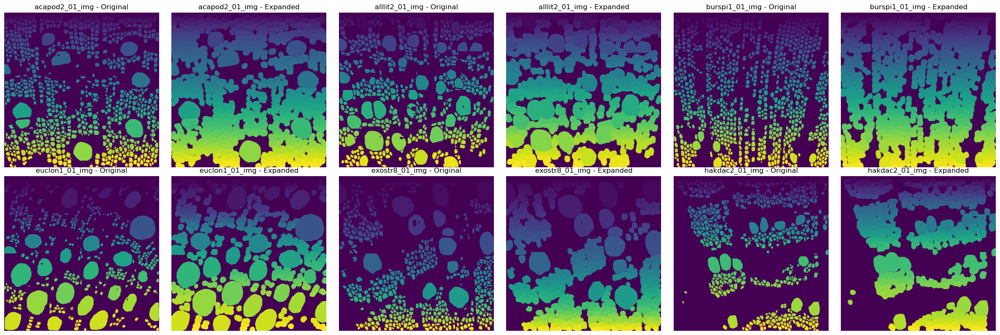

In [7]:
fig, axes = plt.subplots(2, 6, figsize=(24, 8))  # 2行×6列
axes = axes.flatten()

for idx, (fnam, new_labels, expanded_labels) in enumerate(label_results):
    ax1 = axes[2 * idx]
    ax2 = axes[2 * idx + 1]

    ax1.imshow(new_labels)
    ax1.set_title(f"{fnam} - Original")
    ax1.axis('off')

    ax2.imshow(expanded_labels)
    ax2.set_title(f"{fnam} - Expanded")
    ax2.axis('off')

plt.tight_layout()
plt.show()


Predictive maps of cell types were labelled and the morphological elements were obtained from them using the reagionalprops function of SKIMAGE, and then stored in the panda data.

In [8]:
#形質をdfとして

from skimage.measure import regionprops_table
import pandas as pd

all_dfs = []

for (fnam, pred_img), (_, _, expanded_labels) in zip(predictions, label_results):
    print(f"Processing props for {fnam}")

    # regionprops_tableを使って特徴抽出
    props = regionprops_table(
        expanded_labels,
        properties=('label', 'centroid', 'bbox', 'orientation',
                    'axis_major_length', 'axis_minor_length', 'area'),
    )
    df = pd.DataFrame(props)

    # 各ラベル領域のグレイレベル分類
    def get_gray(p):
        output = pred_img[expanded_labels == p]
        out = output[np.isin(output, [64, 128, 192, 255])]
        if len(out) == 0:
            return 0
        return np.argmax(np.bincount(out))

    t1 = time.time()
    label_list = np.unique(expanded_labels)[1:]  # 0を除外
    gray_values = [get_gray(lbl) for lbl in label_list]
    df['gray'] = gray_values
    t2 = time.time()
    print(f"{fnam} : {t2 - t1:.2f} sec")

    # グレイレベル → セルタイプ・色変換辞書
    color = [(0, 0, 0), (1, 159/255, 155/255), (144/255, 229/255, 161/255),
             (161/255, 201/255, 244/255), (1, 180/255, 130/255)]
    cell_type = ['stuff', 'vessel', 'ray', 'fiber', 'parenchyma']
    gray = [0, 64, 128, 192, 255]

    gr_cell_dict = dict(zip(gray, cell_type))
    gr_c_dict = dict(zip(gray, color))

    # セルタイプ・色を列に追加
    df['anatomy'] = df['gray'].map(gr_cell_dict)
    df['color'] = df['gray'].map(gr_c_dict)
    df['image'] = fnam  # 画像名も記録しておく

    # 必要なら保存もできる：
    os.makedirs(os.path.join(raw_dir, "cell_props"), exist_ok=True)
    df.to_csv(os.path.join(raw_dir,"cell_props", f"{fnam}_cell_props.csv"), index=False)
    

    # リストに保存
    all_dfs.append(df)

df_all = pd.concat(all_dfs, ignore_index=True)
df_all.to_csv("all_cell_props_combined.csv", index=False)



Processing props for acapod2_01_img
acapod2_01_img : 0.69 sec
Processing props for alllit2_01_img
alllit2_01_img : 0.46 sec
Processing props for burspi1_01_img
burspi1_01_img : 0.80 sec
Processing props for euclon1_01_img
euclon1_01_img : 0.36 sec
Processing props for exostr8_01_img
exostr8_01_img : 0.47 sec
Processing props for hakdac2_01_img
hakdac2_01_img : 0.50 sec


Image processing in this area has been devised. The reason for this is to prevent misidentification of cell types due to the colour spreading outside the original image when the area is extended.
If there is a neighbouring area that is not well discriminated, it may be defeated by majority decision by the background colour.
In this case, the cells become the background, so if the background colour is chosen, the second colour is chosen for the cell type by majority vote.

link-table
|            | vessel | ray  | fiber | parenchyma |  
| ---------- | ------ | ---- | ----- | ---------- |
| vessel     | 1      | 2    | 3     | 2          |
| ray        | 2      | 4    | 6     | 4          |
| fiber      | 3      | 6    | 9     | 6          |
| parenchyma | 2      | 4    | 6     | 4          |



| cell_type | 'stuff' | 'vessel'             | 'ray'                     | 'fiber'                    | 'parenchyma'        |
| --------- | ------- | -------------------- | ------------------------- | -------------------------- | ------------------- |
| color     | (0,0,0) | （1,159/255,155/255) | (144/255,229/255,161/255) | (161/255,201/255,244/255), | (1,180/255,130/255) |
| gray      | 0       | 64                   | 128                       | 192                        | 255                 |

In [9]:
df_all

,label,centroid-0,centroid-1,bbox-0,bbox-1,bbox-2,bbox-3,orientation,axis_major_length,axis_minor_length,area,gray,anatomy,color,image
0,1,11.550425,252.518226,0,214,27,288,1.541350,74.650826,29.515000,1646.0,192,fiber,"(0.6313725490196078, 0.788235294117647, 0.9568...",acapod2_01_img
1,2,10.889541,458.304008,0,430,27,483,1.465899,49.030973,29.342458,1023.0,192,fiber,"(0.6313725490196078, 0.788235294117647, 0.9568...",acapod2_01_img
2,3,15.438076,795.009881,0,771,36,825,-1.381620,52.495684,38.890584,1518.0,192,fiber,"(0.6313725490196078, 0.788235294117647, 0.9568...",acapod2_01_img
3,4,20.096005,1456.864043,0,1431,46,1478,0.575154,52.520823,42.821858,1677.0,192,fiber,"(0.6313725490196078, 0.788235294117647, 0.9568...",acapod2_01_img
4,5,14.573171,869.605452,0,839,34,895,1.263971,53.129304,35.743113,1394.0,192,fiber,"(0.6313725490196078, 0.788235294117647, 0.9568...",acapod2_01_img
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3871,555,1514.605598,1353.948261,1494,1337,1536,1374,0.445528,48.298616,31.664584,1179.0,192,fiber,"(0.6313725490196078, 0.788235294117647, 0.9568...",hakdac2_01_img
3872,556,1519.469417,721.794452,1492,701,1536,754,1.031469,54.415229,36.972851,1406.0,192,fiber,"(0.6313725490196078, 0.788235294117647, 0.9568...",hakdac2_01_img
3873,557,1521.845528,1393.152149,1504,1370,1536,1416,-1.005264,48.995129,23.603145,861.0,192,fiber,"(0.6313725490196078, 0.788235294117647, 0.9568...",hakdac2_01_img
3874,558,1523.451147,1147.439252,1504,1120,1536,1178,1.391503,54.918063,31.148248,1177.0,192,fiber,"(0.6313725490196078, 0.788235294117647, 0.9568...",hakdac2_01_img


### Save all segmentation results in numpy archive

#修正前の推論結果の.npyは保存する必要なし

"""
res = np.zeros((6,new_labels.shape[0],new_labels.shape[1]))
res[0,:,:] = img_pred
res[1,:,:] = new_labels
res[2,:,:] = cleared_labels
res[3,:,:] = expanded_labels
res[4,:,:] = img_in[:,:,0]
res[5,:,:] = img_in[:,:,0]

np.save(os.path.join(raw_dir, fnam+'_prediction.npy'), res)

***

In [10]:
### Save new annotation in COCO format

Map anatomy data on the new labels.

In [11]:
import copy
import time
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# 保存先ディレクトリの作成
annot_save_dir = os.path.join(base_dir, MODEL_FILE, 'prediction_cleaned')
os.makedirs(annot_save_dir, exist_ok=True)

# 表示用リスト
annotated_images = []

# 処理ループ（new_labels を使用）
for (fnam, new_labels, _), df in zip(label_results, all_dfs):
    print(f"Generating anatomical annotation (unexpanded) for: {fnam}")
    
    # ラベルマップを一次元に flatten
    new_labels_copy = copy.deepcopy(new_labels).flatten()
    new_annotation = np.zeros_like(new_labels_copy, dtype=np.uint8)

    # ラベル番号 → graylevel の変換辞書を作成
    replace_func = {
        int(label): int(gray) for label, gray in zip(df['label'].values, df['gray'].values)
    }

    # マッピング処理
    t1 = time.time()
    replace_result = np.array(list(map(replace_func.get, new_labels_copy)))
    result_index = np.where(replace_result != None)[0]
    new_annotation[result_index] = replace_result[result_index]
    t2 = time.time()
    print(f"{fnam} : annotation completed in {t2 - t1:.2f} sec")

    # ラベル画像に再構成
    newly_annotated_img = new_annotation.reshape(new_labels.shape)

    # 保存
    out_path = os.path.join(annot_save_dir, f"{fnam}_pred_cleaned.png")
    Image.fromarray(newly_annotated_img).save(out_path)

    # 表示用に記録
    annotated_images.append((fnam, newly_annotated_img))



Generating anatomical annotation (unexpanded) for: acapod2_01_img
acapod2_01_img : annotation completed in 1.44 sec
Generating anatomical annotation (unexpanded) for: alllit2_01_img
alllit2_01_img : annotation completed in 1.45 sec
Generating anatomical annotation (unexpanded) for: burspi1_01_img
burspi1_01_img : annotation completed in 1.31 sec
Generating anatomical annotation (unexpanded) for: euclon1_01_img
euclon1_01_img : annotation completed in 1.20 sec
Generating anatomical annotation (unexpanded) for: exostr8_01_img
exostr8_01_img : annotation completed in 1.23 sec
Generating anatomical annotation (unexpanded) for: hakdac2_01_img
hakdac2_01_img : annotation completed in 0.99 sec


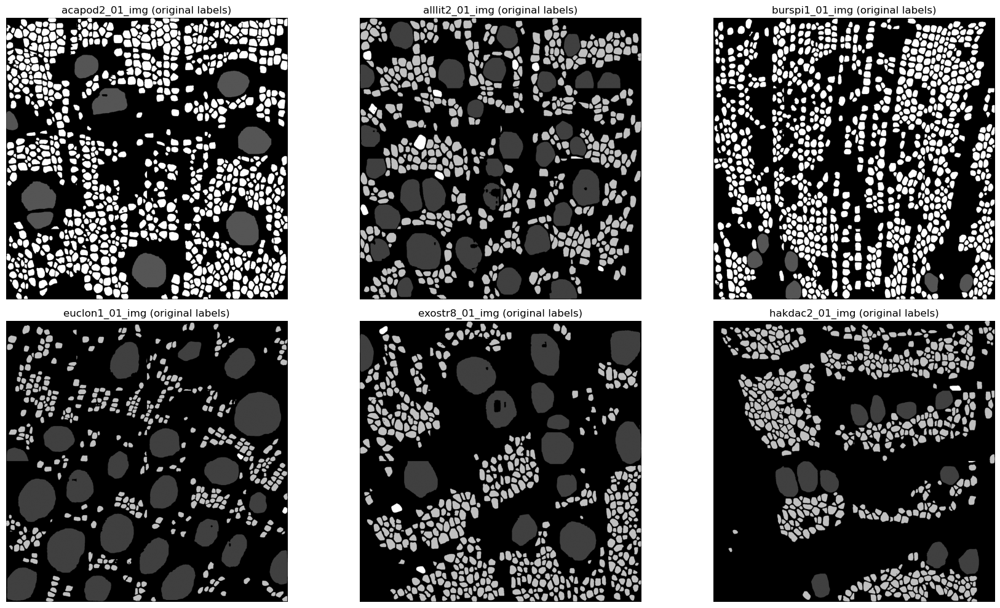

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, (fnam, img) in zip(axes, annotated_images):
    ax.imshow(img, cmap='gray')
    ax.set_title(f"{fnam} (original labels)")
    ax.axis('off')

plt.tight_layout()
plt.show()


Check new labels 

In [13]:
from src.create_annotations import *

# original 2560 x 2560 image 
#data_img = 'dataset/original/Alllit_test_original.png'
#data_img = 'dataset/original/kusunoki.png'


# Label ids of the dataset
category_ids = {
    "stuff" : 0,
    "vessel": 1,
    "ray": 2,
    "fiber": 3,
    "parenchyma": 4
}

# Define which colors match which categories in the images
category_colors = {
    "(0, 0, 0)" : 0, # stuff
    "(64, 64, 64)": 1, # vessel
    "(128, 128, 128)": 2, # ray
    "(192, 192, 192)": 3, # fiber
    "(255, 255, 255)": 4 # parenchyma
}
"""
# Label ids of the dataset
category_ids = {
    "stuff" : 0,
    "unknown": 1,
}

# Define which colors match which categories in the images
category_colors = {
    "(0, 0, 0)" : 0, # stuff
    "(64, 64, 64)": 1 # unknown
}
"""

'\n# Label ids of the dataset\ncategory_ids = {\n    "stuff" : 0,\n    "unknown": 1,\n}\n\n# Define which colors match which categories in the images\ncategory_colors = {\n    "(0, 0, 0)" : 0, # stuff\n    "(64, 64, 64)": 1 # unknown\n}\n'

In [14]:
# Define the ids that are a multiplolygon. In our case: None maybe stuff??
import json
from pathlib import Path

# 複数画像に対応したCOCO変換処理
multipolygon_ids = []  # 通常 None や background の ID を指定

# 保存先ディレクトリ（拡張なしの prediction_cleaned に対応）
annot_json_save_dir = os.path.join(base_dir, MODEL_FILE, 'prediction_cleaned_json')
os.makedirs(annot_json_save_dir, exist_ok=True)

for (fnam, new_labels, _), df in zip(label_results, all_dfs):
    print(f"Generating COCO-style JSON for: {fnam}")
    
    # ラベルマップを1チャンネルgray画像に変換（df['gray']列を利用）
    label_map = np.zeros_like(new_labels, dtype=np.uint8)
    for lbl, gray in zip(df['label'], df['gray']):
        label_map[new_labels == lbl] = gray

    # 入力画像パスを再構築（必要に応じて置き換え）
    data_img = os.path.join(input_dir, fnam + ".png")

    # COCO形式変換
    coco_format = get_coco_json_format()
    coco_format["info"] = info()
    coco_format["categories"] = create_category_annotation(category_ids)

    coco_format["images"], coco_format["annotations"], annotation_cnt = \
        singleshot_annotations_info(label_map, data_img, category_ids, category_colors, multipolygon_ids)

    # 保存
    json_path = os.path.join(annot_json_save_dir, f"{fnam}_annot_coco.json")
    with open(json_path, "w") as outfile:
        json.dump(coco_format, outfile)

    print(f"{fnam}: Created {annotation_cnt} annotations → {json_path}")


Generating COCO-style JSON for: acapod2_01_img
acapod2_01_img: Created 861 annotations → ./inference_results_without_clearborder/512_thin_multidomain_700_epoch.tar/prediction_cleaned_json/acapod2_01_img_annot_coco.json
Generating COCO-style JSON for: alllit2_01_img
alllit2_01_img: Created 544 annotations → ./inference_results_without_clearborder/512_thin_multidomain_700_epoch.tar/prediction_cleaned_json/alllit2_01_img_annot_coco.json
Generating COCO-style JSON for: burspi1_01_img
burspi1_01_img: Created 985 annotations → ./inference_results_without_clearborder/512_thin_multidomain_700_epoch.tar/prediction_cleaned_json/burspi1_01_img_annot_coco.json
Generating COCO-style JSON for: euclon1_01_img
euclon1_01_img: Created 427 annotations → ./inference_results_without_clearborder/512_thin_multidomain_700_epoch.tar/prediction_cleaned_json/euclon1_01_img_annot_coco.json
Generating COCO-style JSON for: exostr8_01_img
exostr8_01_img: Created 520 annotations → ./inference_results_without_clearbo

***

# Validation


1. Ground Truthマスクの読み込み（グレースケール）

2. GTマスクのグレイ値を、モデル側と一致するように変換（gt_gray_remap）

3. 各クラス（stuff以外）ごとに clear_border を適用し、端の細胞を除外

4. GTマスクをクラスID（0〜4）に変換（normalize_mask）

5. 推論マスクを読み込み、同様にクラスIDに変換

6. stuff（クラス0）を除外して以下を計算：

    - IoU（交差／和）

    - Dice係数（F1スコア）

    - Accuracy（正解率）

7. 結果を print で表示

8. Ground Truth と Prediction を比較表示（imshow）

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.measure import label
from skimage.segmentation import clear_border
import os

# ======= ラベル定義 =======
label_mapping = {0: 0, 64: 1, 128: 2, 192: 3, 255: 4}
num_classes = len(label_mapping)
ignore_class = 0  # stuff を無視

# ======= ヘルパー関数 =======
def normalize_mask(mask):
    return np.vectorize(label_mapping.get)(mask)

def remap_gt_gray(mask, remap_dict):
    remapped = np.copy(mask)
    for src, dst in remap_dict.items():
        remapped[mask == src] = dst
    return remapped

def clear_border_cells_per_class(gt_raw):
    gt_filtered = np.zeros_like(gt_raw)
    for gray in [64, 128, 192, 255]:
        binary = (gt_raw == gray)
        labeled = label(binary)
        #cleared = clear_border(labeled)
        gt_filtered[labeled > 0] = gray
    return gt_filtered

def compute_iou(gt, pred, num_classes, ignore_class=None):
    iou_list = []
    for cls in range(num_classes):
        if cls == ignore_class:
            continue
        gt_cls = (gt == cls)
        pred_cls = (pred == cls)
        intersection = np.logical_and(gt_cls, pred_cls).sum()
        union = np.logical_or(gt_cls, pred_cls).sum()
        if union == 0:
            continue
        iou_list.append(intersection / union)
    return np.mean(iou_list), iou_list

def compute_dice(gt, pred, num_classes, ignore_class=None):
    dice_list = []
    for cls in range(num_classes):
        if cls == ignore_class:
            continue
        gt_cls = (gt == cls)
        pred_cls = (pred == cls)
        tp = np.logical_and(gt_cls, pred_cls).sum()
        denom = gt_cls.sum() + pred_cls.sum()
        if denom == 0:
            continue
        dice_list.append(2 * tp / denom)
    return np.mean(dice_list), dice_list

def compute_accuracy(gt, pred, ignore_class=None):
    if ignore_class is None:
        return (gt == pred).sum() / gt.size
    mask = gt != ignore_class
    return (gt[mask] == pred[mask]).sum() / mask.sum()



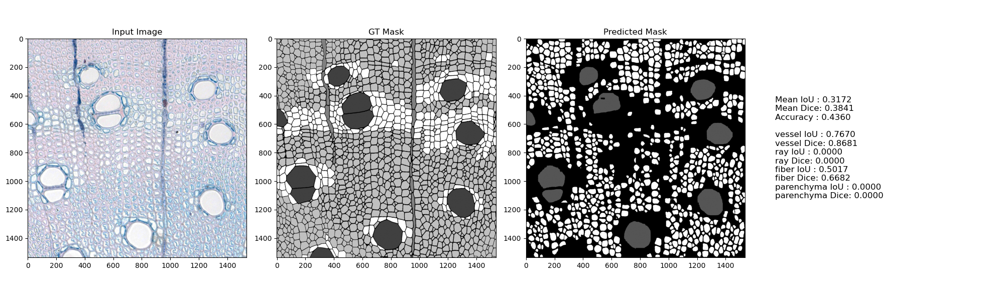

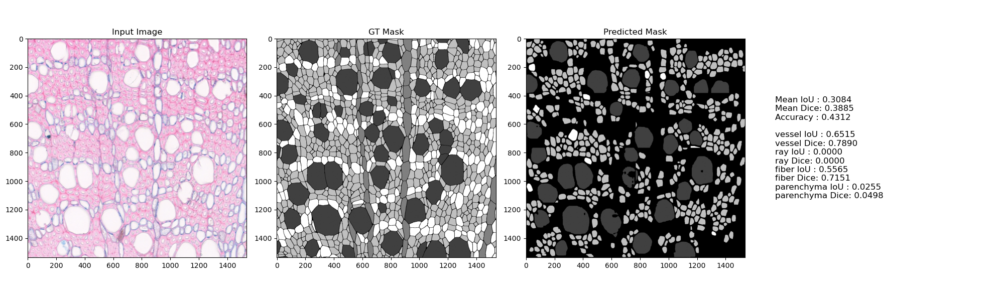

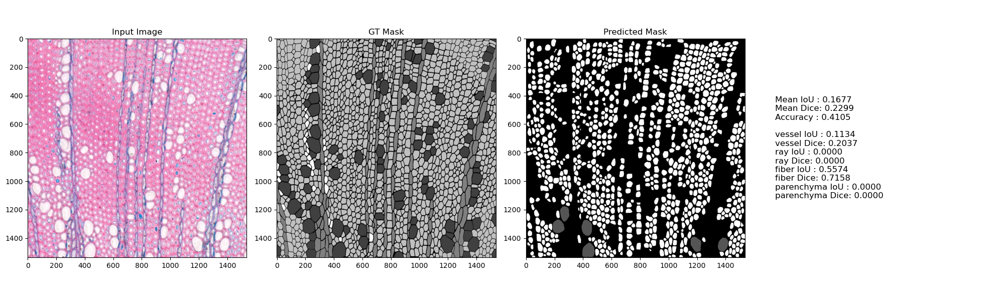

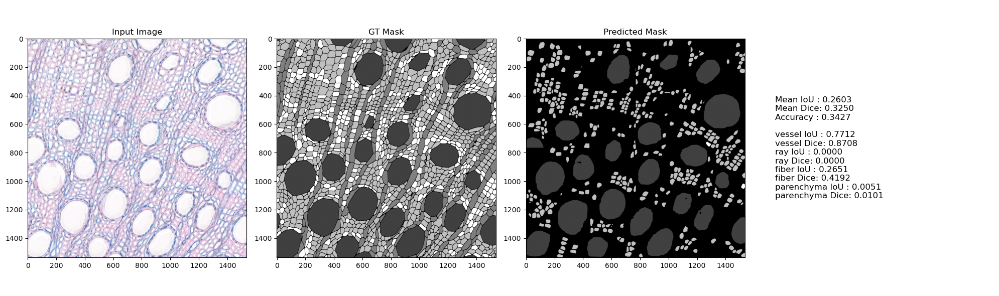

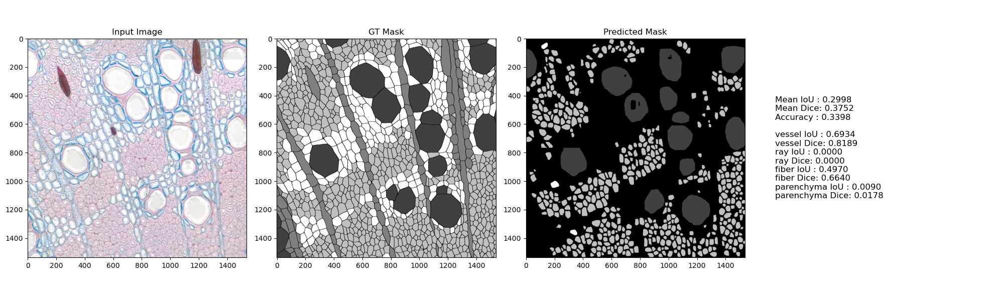

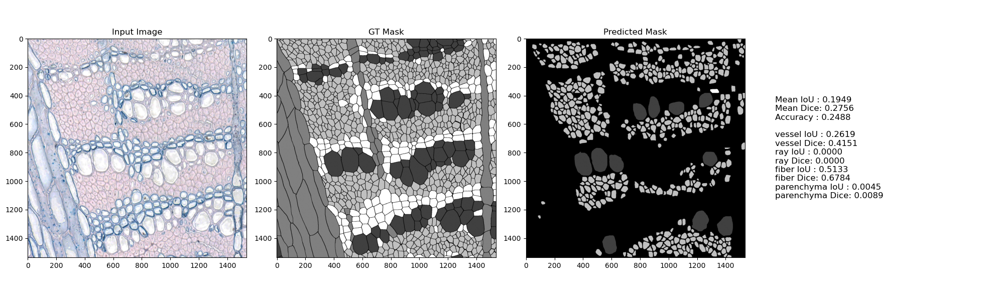

In [16]:
id_to_classname = {v: k for k, v in category_ids.items()}

# ======= ディレクトリ定義 =======
gt_dir = 'dataset/performance_check/mask'
score_dir = os.path.join(base_dir, MODEL_FILE, 'scores')
vis_dir = os.path.join(base_dir, MODEL_FILE, 'visual_comparison')
os.makedirs(score_dir, exist_ok=True)
os.makedirs(vis_dir, exist_ok=True)

# ======= 評価結果保存用リスト =======
score_records = []

# ======= メインループ =======
for idx, (sp, filename) in enumerate(sp_to_filename.items()):
    fnam = os.path.splitext(filename)[0]
    fnam_short = fnam[:-4]

    img_path = os.path.join(input_dir, filename)
    gt_path = os.path.join(gt_dir, fnam_short + "_msk.png")
    pred_dir = os.path.join(base_dir, MODEL_FILE, 'prediction_cleaned')
    pred_path = os.path.join(pred_dir, fnam + "_pred_cleaned.png")

    # 入力とGTの読み込み
    img = np.array(Image.open(img_path).convert("RGB"))
    gt_raw = np.array(Image.open(gt_path).convert("L"))
    pred_raw = np.array(Image.open(pred_path).convert("L"))

    # GT処理（リマップ + 境界除去 + 正規化）
    gt_remap_dict = {0: 64, 64: 128, 128: 192, 192: 255, 255: 0}
    gt_remapped = remap_gt_gray(gt_raw, gt_remap_dict)
    gt_cleared = clear_border_cells_per_class(gt_remapped)
    gt_norm = normalize_mask(gt_cleared)

    # 推論結果も正規化
    pred_norm = normalize_mask(pred_raw)

    # スコア計算
    mean_iou, per_class_iou = compute_iou(gt_norm, pred_norm, num_classes, ignore_class)
    mean_dice, per_class_dice = compute_dice(gt_norm, pred_norm, num_classes, ignore_class)
    acc = compute_accuracy(gt_norm, pred_norm, ignore_class)

    # --- 表示用図作成 ---
    fig, axes = plt.subplots(1, 4, figsize=(20, 6))
    axes[0].imshow(img)
    axes[0].set_title('Input Image')
    axes[1].imshow(gt_norm, cmap='gray')
    axes[1].set_title('GT Mask')
    axes[2].imshow(pred_norm, cmap='gray')
    axes[2].set_title('Predicted Mask')

    # スコアテキスト表示
    text = f"Mean IoU : {mean_iou:.4f}\nMean Dice: {mean_dice:.4f}\nAccuracy : {acc:.4f}\n"
    for cls_id in range(num_classes):
        if cls_id == ignore_class:
            continue
        cls_name = id_to_classname.get(cls_id, f"Class {cls_id}")
        text += f"\n{cls_name} IoU : {per_class_iou[cls_id - 1]:.4f}"
        text += f"\n{cls_name} Dice: {per_class_dice[cls_id - 1]:.4f}"
    axes[3].axis('off')
    axes[3].text(0, 0.5, text, fontsize=12, va='center')

    plt.tight_layout()
    fig.savefig(os.path.join(vis_dir, f"{fnam}_comparison.pdf
    "), dpi=300)
    plt.show()
    plt.close(fig)

    # --- CSV用スコア保存 ---
    record = {
        "filename": fnam,
        "mean_iou": mean_iou,
        "mean_dice": mean_dice,
        "accuracy": acc,
    }
    for cls_id in range(num_classes):
        if cls_id == ignore_class:
            continue
        cls_name = id_to_classname.get(cls_id, f"class{cls_id}")
        record[f"{cls_name}_iou"] = per_class_iou[cls_id - 1]
        record[f"{cls_name}_dice"] = per_class_dice[cls_id - 1]
    score_records.append(record)

# --- 全スコアをCSV保存 ---
df_scores = pd.DataFrame(score_records)
df_scores.to_csv(os.path.join(score_dir, "evaluation_scores.csv"), index=False)